# Tutorial to Qiskit
*Authors:* Javier Argüello-Luengo,

# Using this noteebook
 First time you use the code, you need to install some packages.

In [1]:
!pip install qiskit
!pip install pylatexenc
!pip install qiskit_ibm_runtime
!pip install gem_suite

Defaulting to user installation because normal site-packages is not writeable


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip



   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------------- ------------------------- 3.4/9.3 MB 20.6 MB/s eta 0:00:01
   ------------------------------- -------- 7.3/9.3 MB 19.6 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 17.4 MB/s  0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 18.6 MB/s  0:00:00

   ---------------------------------------- 0/4 [typing-extensions]
   ---------- ----------------------------- 1/4 [stevedore]
   ---------- ----------------------------- 1/4 [stevedore]
   ---------- ----------------------------- 1/4 [stevedore]
   ---------- ----------------------------- 1/4 [stevedore]
   ---------- ----------------------------- 1/4 [stevedore]
   ---------- ----------------------------- 1/4 [stevedore]
   ---------- ----------------------------- 1/4 [stevedore]
   ---------- ----------------------------- 1/4 [stevedore]
   -------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 2.0/2.0 MB 11.9 MB/s  0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 14.5 MB/s  0:00:00
   ---------------------------------------- 0.0/551.8 kB ? eta -:--:--
   ---------------------------------------- 551.8/551.8 kB 5.0 MB/s  0:00:00
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   ---------------------------------------- 3.8/3.8 MB 18.7 MB/s  0:00:00
   ---------------------------------------- 0.0/557.4 kB ? eta -:--:--
   ---------------------------------------- 557.4/557.4 kB 12.5 MB/s  0:00:00

   ----------------------------------------  0/28 [openqasm3]
   ----------------------------------------  0/28 [openqasm3]
   ----------------------------------------  0/28 [openqasm3]
   ------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/528.1 kB ? eta -:--:--
   ---------------------------------------- 528.1/528.1 kB 2.6 MB/s  0:00:00
   ---------------------------------------- 0.0/651.4 kB ? eta -:--:--
   ---------------------------------------- 651.4/651.4 kB 4.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ----------------------------- ---------- 1.6/2.1 MB 8.6 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 7.8 MB/s  0:00:00

   ---------------------------------------- 0/7 [uncertainties]
   ---------------------------------------- 0/7 [uncertainties]
   ----- ---------------------------------- 1/7 [networkx]
   ----- ---------------------------------- 1/7 [networkx]
   ----- ---------------------------------- 1/7 [networkx]
   ----- ---------------------------------- 1/7 [networkx]
   ----- ----------------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


After this installation, go to `Entorno de ejecución` and `Reiniciar sesión`

Now, you should have everything ready for you to use this tutorial in *Google Colab*

# 1. Define the quantum circuit

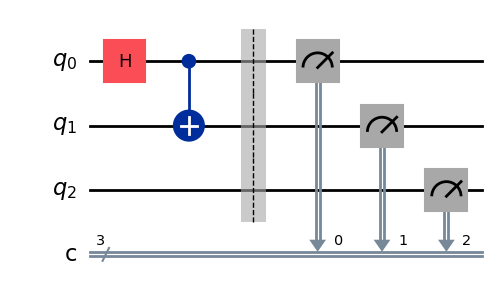

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the circuit (If you are using the code from qIBM composer, you can paste your code between these lines)
#-----------------------------------
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from numpy import pi

qreg_q = QuantumRegister(3, 'q')
creg_c = ClassicalRegister(3, 'c')
circuit = QuantumCircuit(qreg_q, creg_c)

circuit.h(qreg_q[0])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.barrier(qreg_q[0], qreg_q[1], qreg_q[2])
circuit.measure(qreg_q[0], creg_c[0])
circuit.measure(qreg_q[1], creg_c[1])
circuit.measure(qreg_q[2], creg_c[2])
#-----------------------------------------

circuit.draw("mpl")

# 2. Calculate the expected result
For that, we will use a *classical* sampler

In [12]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.primitives import StatevectorSampler
# Transpile circuit
pm = generate_preset_pass_manager(optimization_level=1)
isa_circuit = pm.run(circuit)

# Instantiate Sampler
sampler = StatevectorSampler()
# execute 1 circuit with Sampler
job = sampler.run([isa_circuit], shots=10000)
job_result = job.result()[0]
print(f" > Result class: {type(job_result)}")

# Get counts from the measured qbits
counts = job_result.join_data().get_counts()
print(f"Raw Qiskit output: {counts}") #see that the qbit order is by default reversed

 > Result class: <class 'qiskit.primitives.containers.sampler_pub_result.SamplerPubResult'>
Raw Qiskit output: {'000': 4976, '011': 5024}


We need to digest the results of the mesasurement. You can see that qiskit outputs the qbits in reversed order. The following function deals with this.

In [13]:
def reverse_counts(counts):
  first_key = next(iter(counts))
  n_qubits=len(first_key)
  # We make an ordered list with all possible states
  counts_keys = [bin(i).replace('0b',"") for i in range(2**n_qubits)]
  for i,key in enumerate(counts_keys):
      while len(key)<n_qubits:
          key= "0"+key
      counts_keys[i] = key
  # IMPORTANT: Reversing string such that the states are read from top to bottom, i.e, |q0 q1 q2 ... qn>
  counts_ordered = dict(zip(counts_keys,[0 for i in range(2**n_qubits)]))
  for count in counts:
      counts_ordered[count[::-1]]=counts[count]
  print(f"Formated output: {counts_ordered}")
  return counts_ordered

def plot_counts(counts):
  # We load the results of our measurement
  plt.ylabel("Counts")
  x_labels = ["|"+key+r"$\rangle$" for key in counts.keys()]
  plt.xlabel("State")
  plt.title("Not normalized probability distribution function")
  plt.bar(x_labels, counts.values())

Formated output: {'000': 4976, '001': 0, '010': 0, '011': 0, '100': 0, '101': 0, '110': 5024, '111': 0}


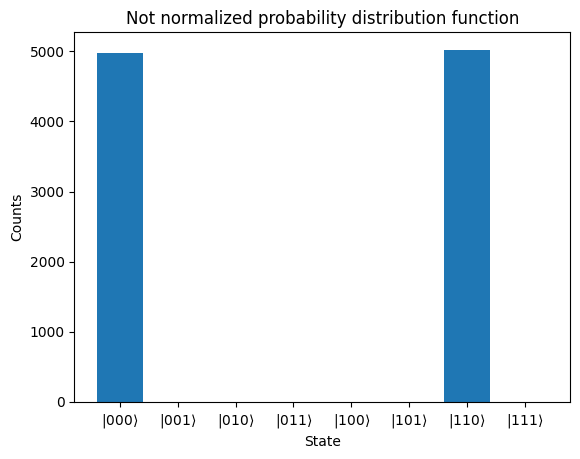

In [14]:
# We can now plot a histogram with the measured outputs (we put the correct order before)
counts_ordered=reverse_counts(counts)
plot_counts(counts_ordered)

In [15]:
#THIS WILL ONLY WORK FOR CIRCUITS WITH 3 MEASURED QBITS. Redefine it otherwise

# You can access the counts if needed (right order)
counts_ordered=reverse_counts(counts)
print(f"The state |000> has been measured {counts_ordered['000']} times")

# From this, you can calculate probabilities. For example, the probability of the first qbit bein zero
total_counts=np.sum(list(counts_ordered.values()))
count_firstQbit_in0=0
for i in range(2):
  for j in range(2):
      count_firstQbit_in0 += counts_ordered['0'+str(i)+str(j)]
print(f"The probability of measuring the first qubit in state |0> is {count_firstQbit_in0/total_counts :.4f}")

Formated output: {'000': 4976, '001': 0, '010': 0, '011': 0, '100': 0, '101': 0, '110': 5024, '111': 0}
The state |000> has been measured 4976 times
The probability of measuring the first qubit in state |0> is 0.4976


# 3. Now, we execute the calculation in a real quantum computer.
First , we fill in the "token" field with our personal API token

In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from gem_suite import PlaquetteLattice

# The key is already saved on this PC, so no token is needed here.
service = QiskitRuntimeService(instance="open-instance")


Backend is: ibm_fez
Number of qubits in backend: 156
Number of qubits in plaquette lattice: 144
Number of plaquettes: 21


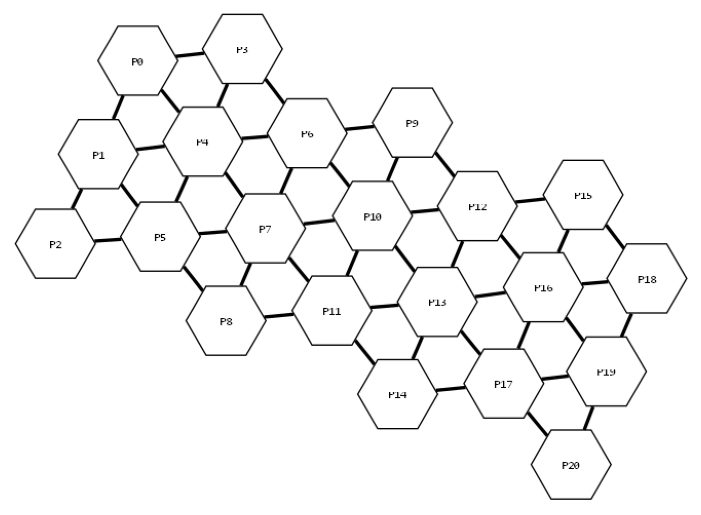

In [2]:
#backend = service.backend("ibm_brisbane") #you can specify the quantum backend
backend = service.least_busy(operational=True, simulator=False) #you can also take the less busy one

plaquette_lattice = PlaquetteLattice.from_coupling_map(backend.coupling_map)
print(f"Backend is: {backend.name}")
print(f"Number of qubits in backend: {backend.num_qubits}")
print(f"Number of qubits in plaquette lattice: {len(list(plaquette_lattice.qubits()))}")
print(f"Number of plaquettes: {len(list(plaquette_lattice.plaquettes()))}")

plaquette_lattice.draw_plaquettes() #schematic representation of the plaquette

You can retrieve information about individual plaquettes, such as the qubits they contain, using the `plaquettes` method.

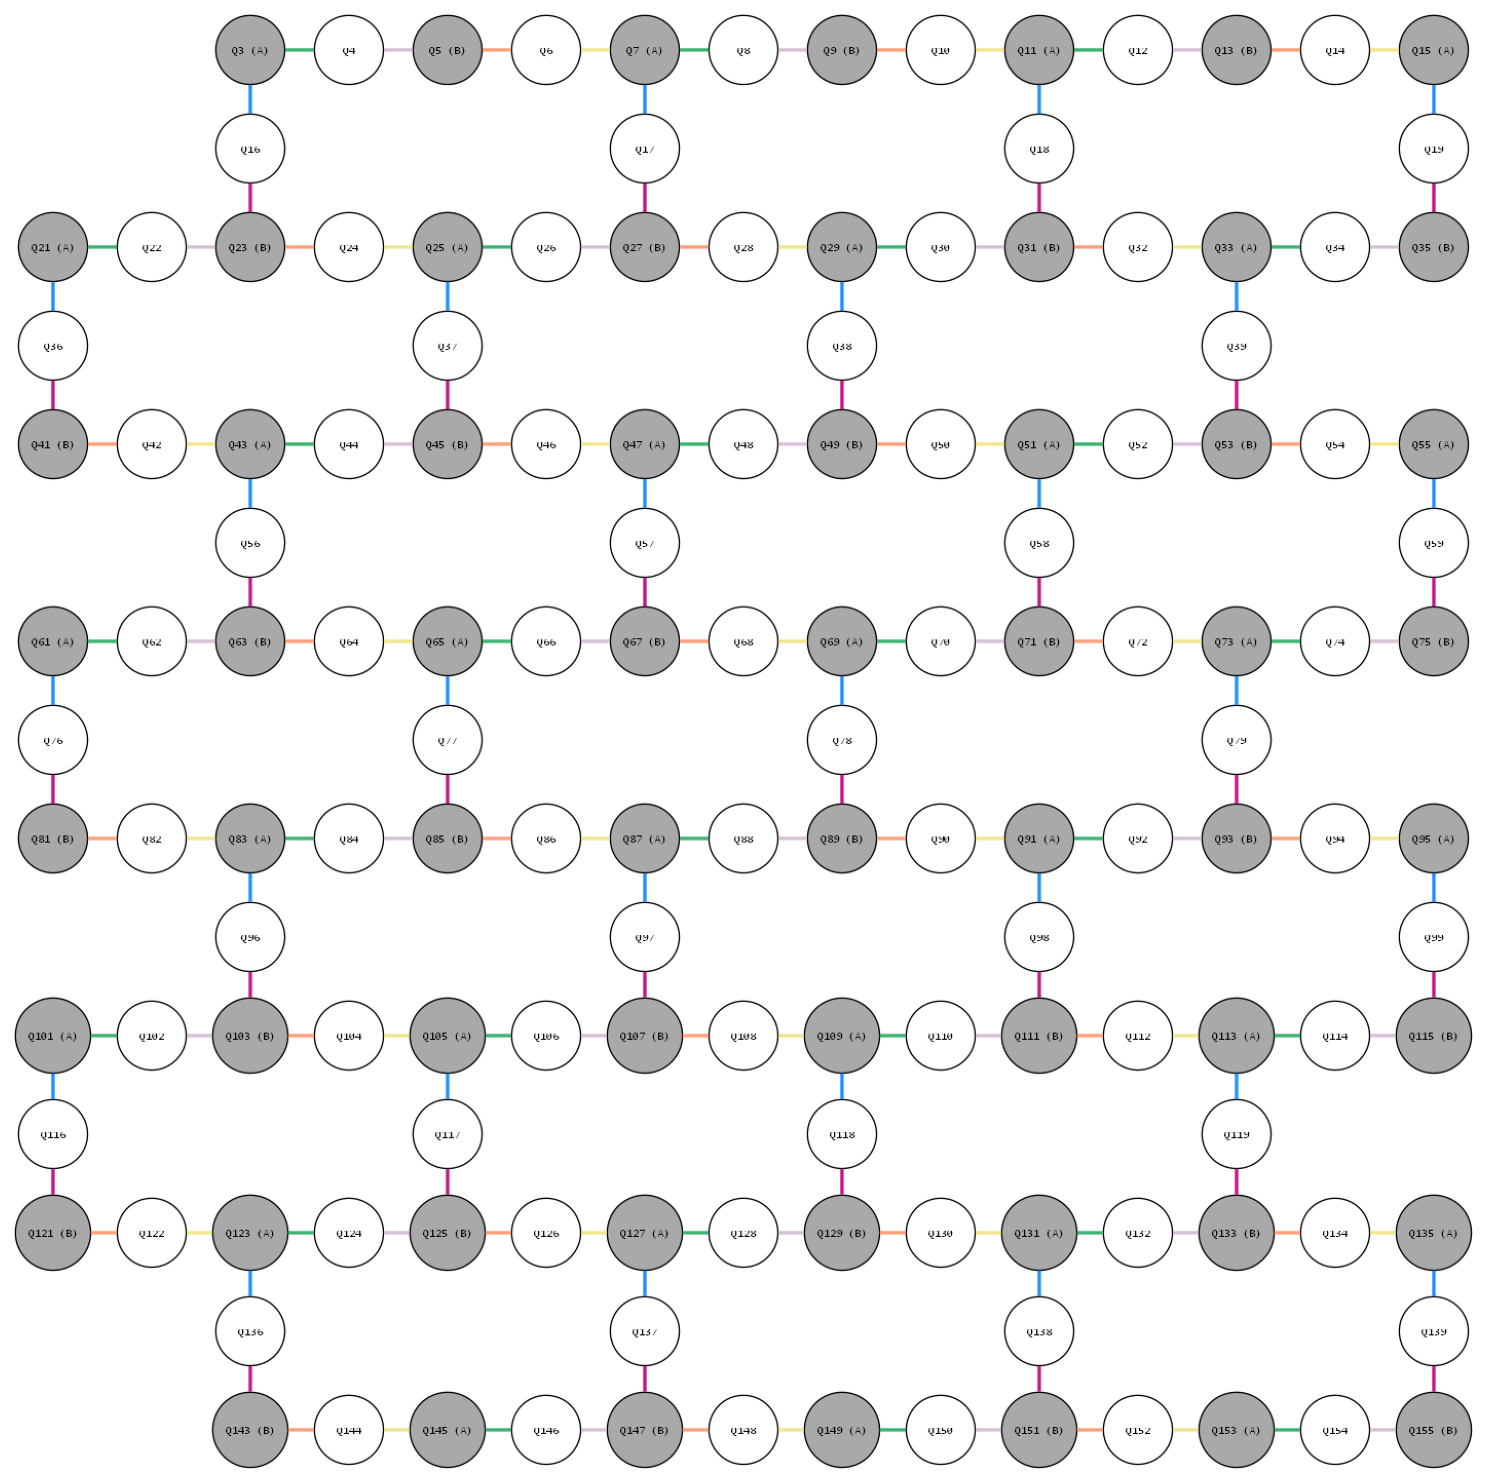

In [3]:
plaquette_lattice.draw_qubits() #scheme of all qbits

We can also check the properties of individual qubits:

`T1` deals with the lifetime of the qubit and asks how long the one state can be distinguished from the zero state

`T2` deals with the phase coherence of the qubit.

In [4]:
properties=backend.properties()
for i in range(5):
  qubit_prop=properties.qubit_property(i)
  print(f"qbit {i} has T1={qubit_prop['T1'][0] :.5f}, T2={qubit_prop['T2'][0] :.5f} and readout err. {qubit_prop['readout_error'][0] :.4f}")

qbit 0 has T1=0.00006, T2=0.00005 and readout err. 0.0293
qbit 1 has T1=0.00021, T2=0.00015 and readout err. 0.0254
qbit 2 has T1=0.00017, T2=0.00013 and readout err. 0.0039
qbit 3 has T1=0.00017, T2=0.00017 and readout err. 0.0264
qbit 4 has T1=0.00016, T2=0.00013 and readout err. 0.0054


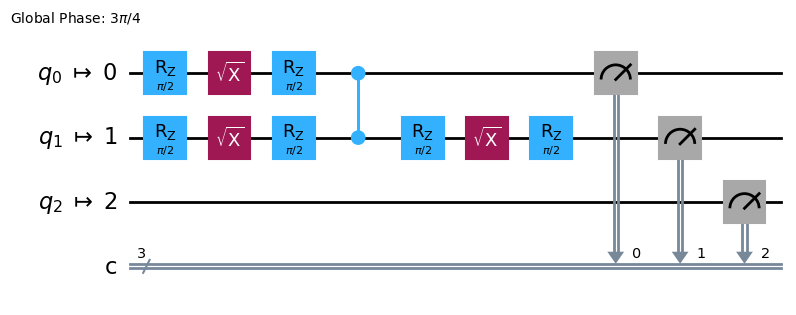

In [7]:
from qiskit.transpiler import generate_preset_pass_manager

# IMPORTANT: if we want to control the mapping physical-virtual qubit, the key is in the initial_layout parameter.
pm = generate_preset_pass_manager(optimization_level=1, backend=backend) #, initial_layout=[0,3,2]) #One can add the last option to impose our logical qbits in qbits 0, 3 and 2 of the backend
isa_circuit = pm.run(circuit)
# This drawing is the actual implementation in the machine!!
isa_circuit.draw("mpl", idle_wires=False, plot_barriers=False)

In [8]:
# We now use our quantum backend to evaluate the circuit
sampler = Sampler(backend)
job_qpu = sampler.run([isa_circuit]) #shots=4000)
job_id = job_qpu.job_id()
print(f"job id: {job_id}")

job id: dbrel46jjaos73aiujqg


QPU output: {'011': 1871, '000': 1990, '010': 117, '001': 114, '100': 2, '111': 2}
Formated output: {'000': 1990, '001': 2, '010': 117, '011': 0, '100': 114, '101': 0, '110': 1871, '111': 2}


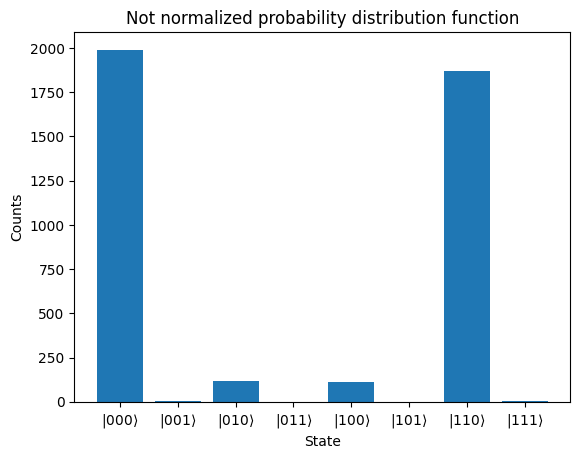

In [16]:
#job_id="cznv0f1rxz8g008dh7pg"
job_qpu = service.job(job_id) #you can load previous jobs if needed

if job_qpu.done():
  job_result_qpu = job_qpu.result()[0]
  # Get counts from the measured qbits
  counts_qpu = job_result_qpu.join_data().get_counts()
  # counts_qpu = job_result_qpu.data.c1.get_counts() # alternative way to get counts when you have multiple classical registers and only want the result form "c1"
  print(f"QPU output: {counts_qpu}") #see that the qbit order is by default reversed
  counts_qpu_ordered=reverse_counts(counts_qpu)
  plot_counts(counts_qpu_ordered)
else:
  print("Job not done yet. You may need some time for the backend to run you circuit")

In [17]:
#THIS WILL ONLY WORK FOR CIRCUITS WITH 3 QBITS. Redefine it otherwise

# You can access the counts if needed (right order)
counts_qpu_ordered=reverse_counts(counts_qpu)
print(f"The state |000> has been measured {counts_qpu_ordered['000']} times")

# From this, you can calculate probabilities. For example, the probability of errors
total_counts=np.sum(list(counts_qpu_ordered.values()))
count_correctQbits=counts_qpu_ordered['000']+counts_qpu_ordered['110']
print(f"The probability of spin flip errors is {1-count_correctQbits/total_counts :.4f}")

Formated output: {'000': 1990, '001': 2, '010': 117, '011': 0, '100': 114, '101': 0, '110': 1871, '111': 2}
The state |000> has been measured 1990 times
The probability of spin flip errors is 0.0574
